In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

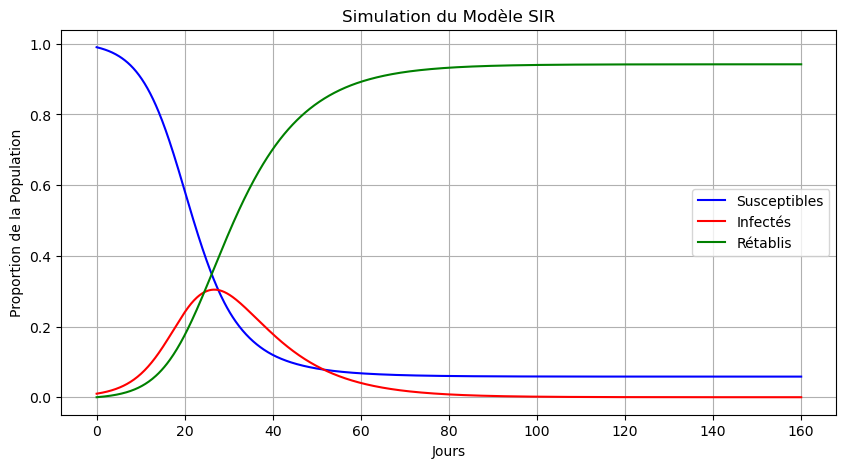

In [4]:


# Définition du modèle SIR
def sir_model(t, y, beta, gamma):
    S, I, R = y  # Extraction des variables
    dSdt = -beta * S * I  # Variation des susceptibles
    dIdt = beta * S * I - gamma * I  # Variation des infectés
    dRdt = gamma * I  # Variation des rétablis
    return [dSdt, dIdt, dRdt]

# Paramètres du modèle
beta = 0.3   # Taux d'infection
gamma = 0.1  # Taux de guérison

# Conditions initiales
S0 = 0.99  # 99% de la population est susceptible
I0 = 0.01  # 1% de la population est infectée
R0 = 0.0   # Aucun rétabli au début

# Période de simulation
t_span = (0, 160)  # Simulation sur 160 jours
t_eval = np.linspace(t_span[0], t_span[1], 1000)  # Points de temps pour l'évaluation

# Résolution numérique des équations
solution = solve_ivp(
    sir_model, t_span, [S0, I0, R0], args=(beta, gamma), t_eval=t_eval
)

# Extraction des résultats
S, I, R = solution.y

# Tracé des courbes
plt.figure(figsize=(10, 5))
plt.plot(solution.t, S, label="Susceptibles", color='blue')
plt.plot(solution.t, I, label="Infectés", color='red')
plt.plot(solution.t, R, label="Rétablis", color='green')
plt.xlabel("Jours")
plt.ylabel("Proportion de la Population")
plt.title("Simulation du Modèle SIR")
plt.legend()
plt.grid()
plt.show()
